# SNN Motion Detection - Simple and Reichardt

---

## Setup

In [ ]:
%%time

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
CPU times: user 754 ms, sys: 119 ms, total: 873 ms
Wall time: 20.3 s


In [ ]:
%%time

!pip install snntorch pyyaml -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.6/125.6 kB 12.9 MB/s eta 0:00:00
CPU times: user 1.29 s, sys: 215 ms, total: 1.51 s
Wall time: 4.82 s


In [ ]:
%%time

PROJECT_PATH = '/content/drive/MyDrive/snn1_notebooks'

import sys
sys.path.append(f'{PROJECT_PATH}/common')
sys.path.append(f'{PROJECT_PATH}/data_generation')
sys.path.append(f'{PROJECT_PATH}/part1_snnTorch')

CPU times: user 23 µs, sys: 4 µs, total: 27 µs
Wall time: 28.8 µs


In [ ]:
%%time

import yaml
with open(f'{PROJECT_PATH}/common/config.yaml', 'r') as f:
    config = yaml.safe_load(f)

CPU times: user 18.5 ms, sys: 3.12 ms, total: 21.6 ms
Wall time: 2.52 s


In [ ]:
%%time

import numpy as np
import matplotlib.pyplot as plt
import torch
import os

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

Using device: cuda
CPU times: user 2.14 s, sys: 569 ms, total: 2.71 s
Wall time: 9.22 s


## Import Modules

In [ ]:
%%time

from data import Data
from data_utils import process_events, generate_batch, generate_dataset, get_data_info
from snn_model import SimpleMotionSNN, ReichardtMotionSNN, classify_function, count_parameters, create_model, print_model_summary
from snn_training import train_model, load_model_checkpoint, print_training_summary
from snn_evaluation import full_evaluation, plot_training_history, plot_spike_activity, evaluate_model, compute_metrics, CLASS_NAMES

CPU times: user 1.18 s, sys: 171 ms, total: 1.35 s
Wall time: 5.96 s


## Data Generator

In [ ]:
%%time

data_generator = Data()

test_events_linear, test_labels_linear = data_generator.get(source='linear', num_samples=10)
print(f'Linear: {len(test_events_linear)} samples')

test_events_circular, test_labels_circular = data_generator.get(source='circular', num_samples=10)
print(f'Circular: {len(test_events_circular)} samples')

test_events_dvs128, test_labels_dvs128 = data_generator.get(source='dvs128', num_samples=20)
print(f'DVS128: {len(test_events_dvs128)} samples, labels: {set(test_labels_dvs128)}')

Linear: 10 samples
Circular: 10 samples
Loading DVS128 data from /content/drive/MyDrive/snn1_notebooks/data_generation/data/dvs128_all.npz...
Loaded 1341 samples into memory.
DVS128: 20 samples, labels: {np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(9), np.int64(10)}
CPU times: user 10 s, sys: 8.48 s, total: 18.5 s
Wall time: 3min 44s


In [ ]:
%%time

print('Linear Batch:')
batch_data, batch_labels = generate_batch(data_generator, batch_size=8, config=config, source='linear')
get_data_info(batch_data, batch_labels)

print('\nDVS128 Batch:')
batch_data, batch_labels = generate_batch(data_generator, batch_size=8, config=config, source='dvs128')
get_data_info(batch_data, batch_labels)

Linear Batch:
Data shape: torch.Size([50, 8, 16384])
Labels shape: torch.Size([8])
Num samples: 8
Timesteps: 50
Receptors: 16384
Label distribution: {0: 4, 1: 4}
Data range: [-1.00, 1.00]

DVS128 Batch:
Data shape: torch.Size([50, 8, 16384])
Labels shape: torch.Size([8])
Num samples: 8
Timesteps: 50
Receptors: 16384
Label distribution: {2: 1, 3: 2, 4: 1, 6: 1, 8: 2, 9: 1}
Data range: [-1.00, 1.00]
CPU times: user 103 ms, sys: 55.3 ms, total: 159 ms
Wall time: 306 ms


## Model Summaries

In [ ]:
%%time

print('Simple (LIF) Model')
print('-' * 50)

# 2-classes (Linear/Circular)
print('\n--- 2 Classes (Linear/Circular) ---')
model_simple_2 = create_model(config, DEVICE, model_type='simple', num_classes=2)
print_model_summary(config, model_type='simple')
count_parameters(model_simple_2)

# 11-classes (DVS128)
print('\n--- 11 Classes (DVS128) ---')
model_simple_11 = create_model(config, DEVICE, model_type='simple', num_classes=11)
print(f"Output layer: fc_out.weight [{11}, 32] = 352 params")
print(f"Output layer: fc_out.bias [{11}] = 11 params")
print(f"Total: {sum(p.numel() for p in model_simple_11.parameters()):,} parameters")

print('\n')

print('Reichardt Model')
print('-' * 50)

# 2-classes
print('\n--- 2 Classes (Linear/Circular) ---')
model_reichardt_2 = create_model(config, DEVICE, model_type='reichardt', num_classes=2)
print_model_summary(config, model_type='reichardt')
count_parameters(model_reichardt_2)

# 11-classes (DVS128)
print('\n--- 11 Classes (DVS128) ---')
model_reichardt_11 = create_model(config, DEVICE, model_type='reichardt', num_classes=11)
print(f"Output layer: fc_out.weight [{11}, 64] = 704 params")
print(f"Output layer: fc_out.bias [{11}] = 11 params")
print(f"Total: {sum(p.numel() for p in model_reichardt_11.parameters()):,} parameters")

Simple (LIF) Model
--------------------------------------------------

--- 2 Classes (Linear/Circular) ---
Model Summary
--------------------------------------------------

Architecture: SimpleMotionSNN
  Input: 16384 receptors
  Hidden: 32 neurons × 2 layers
  Output: 2 classes
  Beta: 0.9
  Slope: 25

Input shape: [50, batch, 16384]
Output shape: [50, batch, 2]

Classification: argmax of spike counts over time
Layer                Shape                          Parameters
------------------------------------------------------------
fc1.weight           [32, 16384]                       524,288
fc1.bias             [32]                                   32
fc2.weight           [32, 32]                            1,024
fc2.bias             [32]                                   32
fc_out.weight        [2, 32]                                64
fc_out.bias          [2]                                     2
------------------------------------------------------------
Total                

## Training Parameters

In [ ]:
%%time

NUM_EPOCHS = config['training']['num_epochs']
BATCH_SIZE = config['training']['batch_size']
PATIENCE = config['training']['patience']

CHECKPOINT_DIR = f"{PROJECT_PATH}/{config['paths']['checkpoints_part1']}"
FIGURES_DIR = f"{PROJECT_PATH}/{config['paths']['figures_part1']}"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f'Epochs: {NUM_EPOCHS}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Patience: {PATIENCE}')

Epochs: 50
Batch size: 32
Patience: 10
CPU times: user 677 µs, sys: 1.4 ms, total: 2.07 ms
Wall time: 1.31 s


## Train: Simple and Reichardt on All Sources

In [ ]:
%%time

all_results = {}
MODEL_TYPES = ['simple', 'reichardt']

SOURCE_CONFIG = {
    'linear': {'num_classes': config['data']['num_classes'], 'train_batches': 50, 'val_batches': 10},
    'circular': {'num_classes': config['data']['num_classes'], 'train_batches': 50, 'val_batches': 10},
    'dvs128': {'num_classes': config['data']['dvs128_num_classes'], 'train_batches': 20, 'val_batches': 5}
}

for model_type in MODEL_TYPES:
    print(f'# Model: {model_type.upper()}')
    print('#' * 50)

    all_results[model_type] = {}

    for source in ['linear', 'circular', 'dvs128']:
        print(f'Training: {model_type.upper()} on {source.upper()}')
        print('-' * 50)

        src_config = SOURCE_CONFIG[source]
        num_classes = src_config['num_classes']
        train_batches = src_config['train_batches']
        val_batches = src_config['val_batches']

        print(f'Classes: {num_classes}, Train batches: {train_batches}')

        model = create_model(config, DEVICE, model_type=model_type, num_classes=num_classes)
        print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

        checkpoint_dir = f'{CHECKPOINT_DIR}/{model_type}/{source}'
        os.makedirs(checkpoint_dir, exist_ok=True)

        def make_generate_batch_fn(src):
            def fn(dg, bs, cfg):
                return generate_batch(dg, bs, cfg, source=src)
            return fn

        generate_batch_fn = make_generate_batch_fn(source)

        history = train_model(
            model=model,
            data_generator=data_generator,
            config=config,
            device=DEVICE,
            generate_batch_fn=generate_batch_fn,
            num_epochs=NUM_EPOCHS,
            batch_size=BATCH_SIZE,
            train_batches=train_batches,
            val_batches=val_batches,
            patience=PATIENCE,
            checkpoint_dir=checkpoint_dir,
            verbose=True
        )

        best_model_path = f'{checkpoint_dir}/model_best.pth'
        load_model_checkpoint(model, None, best_model_path, DEVICE)

        labels, predictions, spike_counts = evaluate_model(
            model, data_generator, config, DEVICE,
            num_batches=10, batch_size=32,
            generate_batch_fn=generate_batch_fn
        )

        class_names = CLASS_NAMES.get(source, None)
        metrics = compute_metrics(labels, predictions, target_names=class_names)

        all_results[model_type][source] = {
            'model': model,
            'history': history,
            'metrics': metrics,
            'best_val_acc': max(history['val_acc']),
            'test_acc': metrics['accuracy'],
            'num_classes': num_classes
        }

        print(f'\n{model_type.upper()} on {source.upper()} - Test Accuracy: {metrics["accuracy"]:.2%}')

print('# Training Complete')

# Model: SIMPLE
##################################################
Training: SIMPLE on LINEAR
--------------------------------------------------
Classes: 2, Train batches: 50
Parameters: 525,442
Start training...
Epoch   1/50 | Train Loss: 0.6931, Acc: 50.00% | Val Loss: 0.6931, Acc: 50.00%
         ↳ New best model saved! (val_acc: 50.00%)
Epoch   2/50 | Train Loss: 0.6931, Acc: 50.00% | Val Loss: 0.6931, Acc: 50.00%
Epoch   3/50 | Train Loss: 0.6931, Acc: 50.00% | Val Loss: 0.6931, Acc: 50.00%
Epoch   4/50 | Train Loss: 0.6935, Acc: 56.38% | Val Loss: 0.6949, Acc: 56.56%
         ↳ New best model saved! (val_acc: 56.56%)
Epoch   5/50 | Train Loss: 0.6920, Acc: 71.25% | Val Loss: 0.6894, Acc: 79.38%
         ↳ New best model saved! (val_acc: 79.38%)
Epoch   6/50 | Train Loss: 0.6832, Acc: 79.88% | Val Loss: 0.6713, Acc: 79.38%
Epoch   7/50 | Train Loss: 0.6544, Acc: 83.75% | Val Loss: 0.6300, Acc: 88.44%
         ↳ New best model saved! (val_acc: 88.44%)
Epoch   8/50 | Train Loss: 0.6

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Results

In [ ]:
%%time

print('Results: Simple and Reichardt')
print('-' * 50)
print(f'{"Source":<12} {"Classes":<10} {"Model":<12} {"Epochs":<10} {"Best Val Acc":<15} {"Test Acc":<15}')

for source in ['linear', 'circular', 'dvs128']:
    for model_type in MODEL_TYPES:
        results = all_results[model_type][source]
        epochs = len(results['history']['train_loss'])
        num_classes = results['num_classes']
        val_acc = results['best_val_acc']
        test_acc = results['test_acc']
        print(f'{source:<12} {num_classes:<10} {model_type:<12} {epochs:<10} {val_acc:<15.2%} {test_acc:<15.2%}')

Results: Simple and Reichardt
--------------------------------------------------
Source       Classes    Model        Epochs     Best Val Acc    Test Acc       
linear       2          simple       50         100.00%         98.44%         
linear       2          reichardt    32         100.00%         100.00%        
circular     2          simple       31         98.75%          96.88%         
circular     2          reichardt    34         97.50%          96.25%         
dvs128       11         simple       50         100.00%         94.38%         
dvs128       11         reichardt    24         60.62%          46.56%         
CPU times: user 118 µs, sys: 26 µs, total: 144 µs
Wall time: 137 µs


In [ ]:
%%time

print('Test Accuracy')
print('-' * 50)
print(f'{"Source":<15} {"Simple":<20} {"Reichardt":<20} {"Winner":<15}')

for source in ['linear', 'circular', 'dvs128']:
    simple_acc = all_results['simple'][source]['test_acc']
    reichardt_acc = all_results['reichardt'][source]['test_acc']

    if simple_acc > reichardt_acc:
        winner = 'Simple'
    elif reichardt_acc > simple_acc:
        winner = 'Reichardt'
    else:
        winner = 'Tie'

    print(f'{source:<15} {simple_acc:<20.2%} {reichardt_acc:<20.2%} {winner:<15}')

Test Accuracy
--------------------------------------------------
Source          Simple               Reichardt            Winner         
linear          98.44%               100.00%              Reichardt      
circular        96.88%               96.25%               Simple         
dvs128          94.38%               46.56%               Simple         
CPU times: user 95 µs, sys: 21 µs, total: 116 µs
Wall time: 108 µs


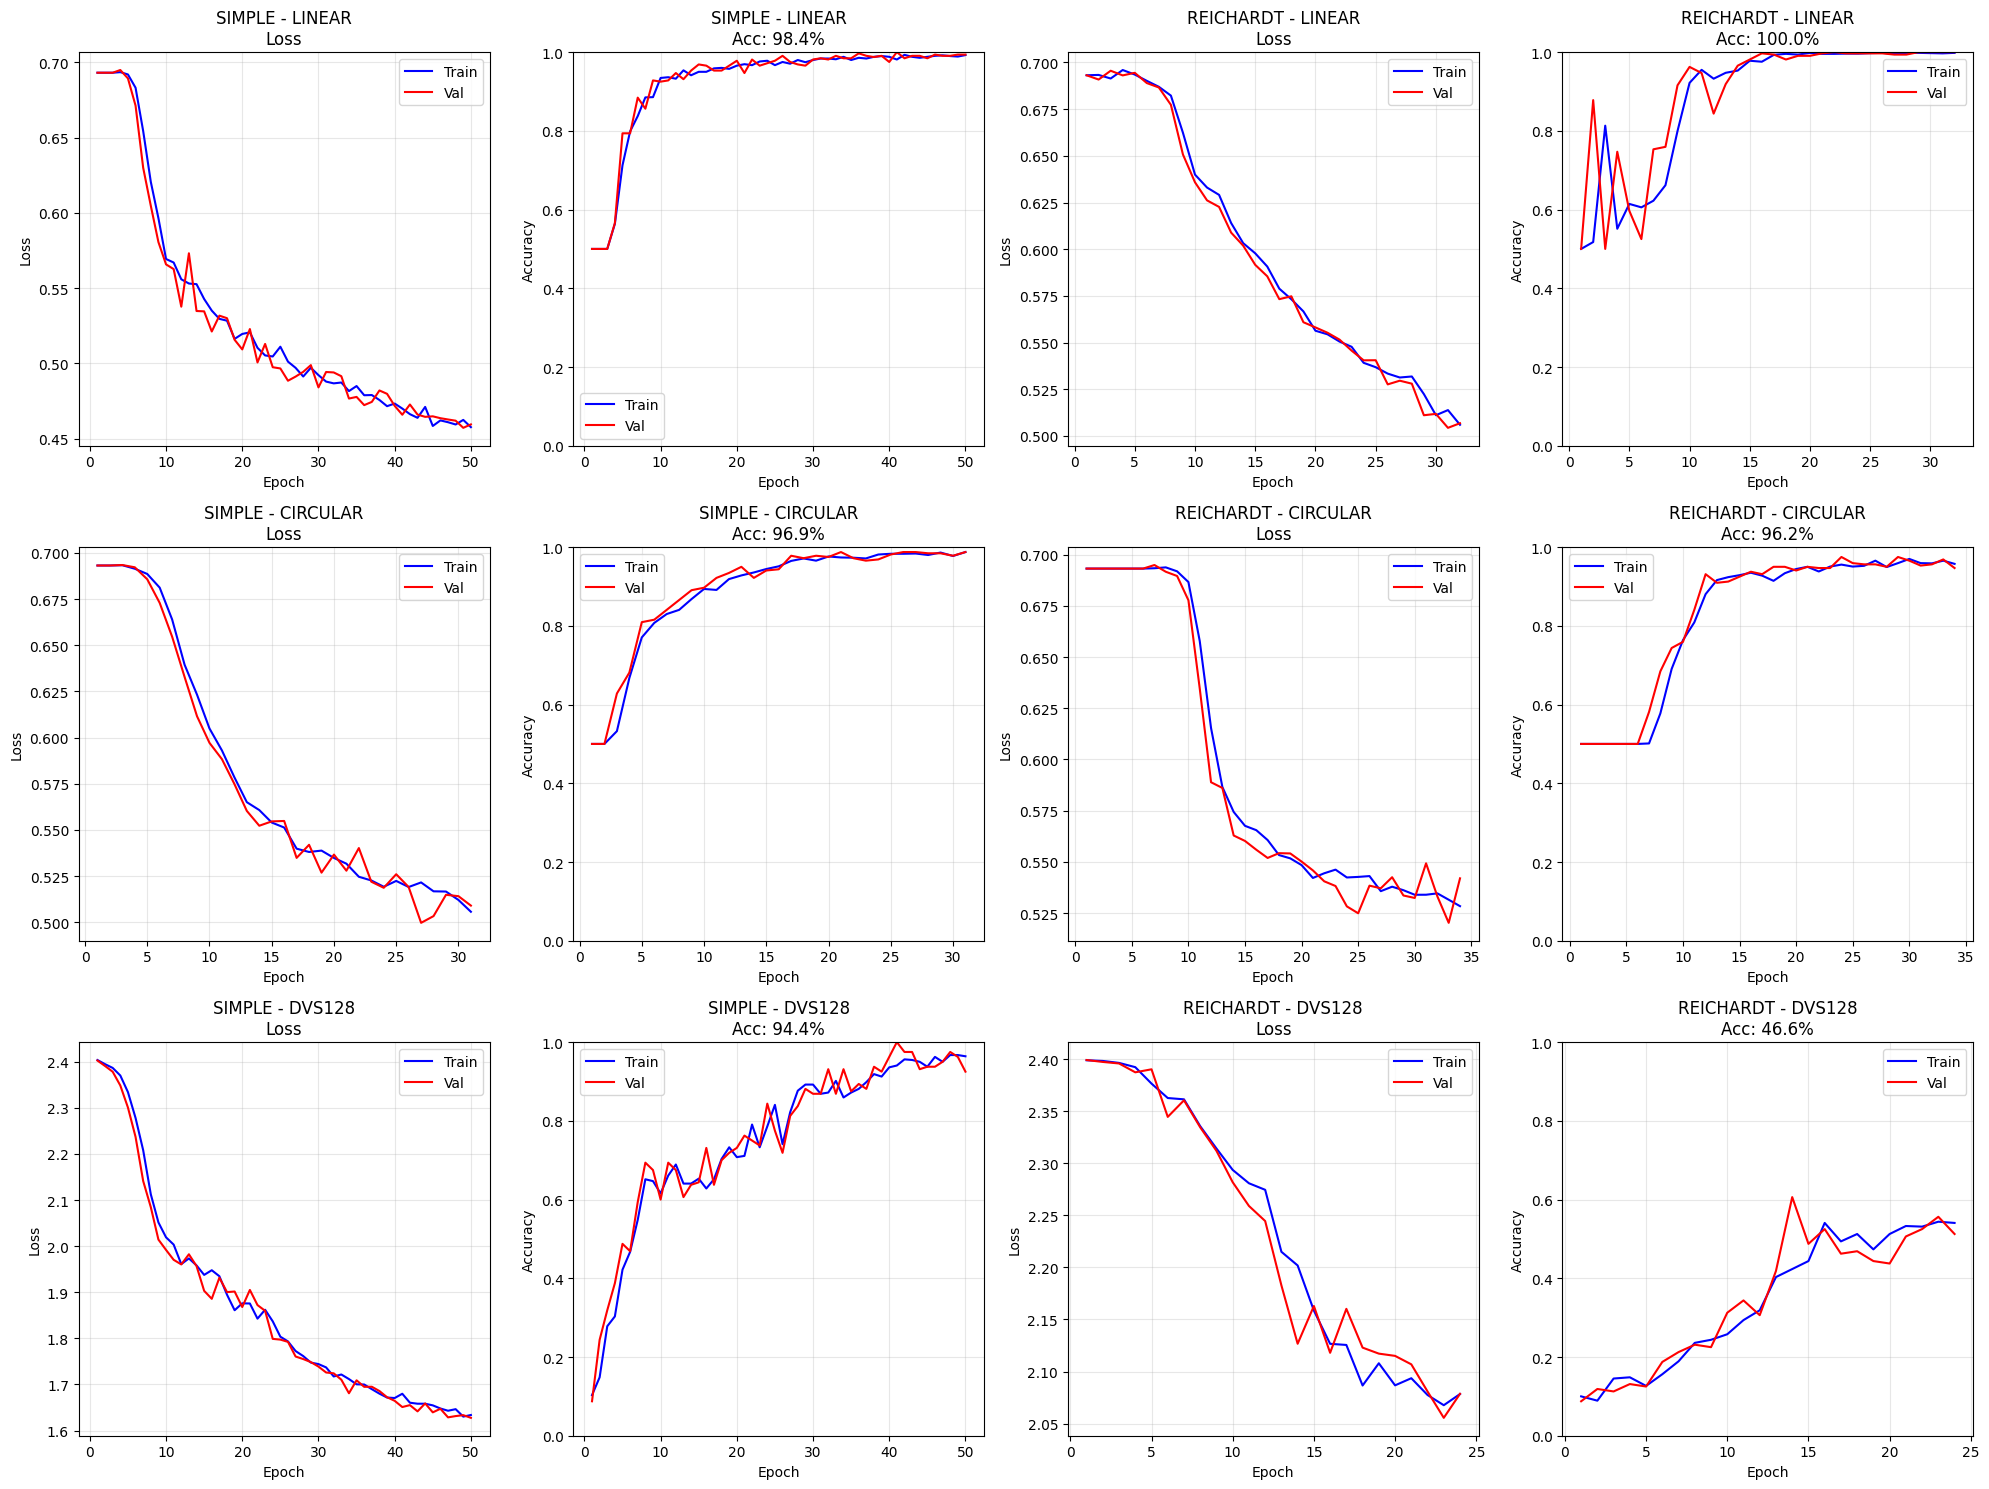

Saved: /content/drive/MyDrive/snn1_notebooks/results/part1_snnTorch/figures/simple_vs_reichardt_all.png
CPU times: user 3.53 s, sys: 64.5 ms, total: 3.59 s
Wall time: 4.85 s


In [ ]:
%%time

fig, axes = plt.subplots(3, 4, figsize=(20, 15))

sources = ['linear', 'circular', 'dvs128']

for row, source in enumerate(sources):
    for col, model_type in enumerate(MODEL_TYPES):
        results = all_results[model_type][source]
        history = results['history']
        epochs = range(1, len(history['train_loss']) + 1)

        ax_loss = axes[row, col * 2]
        ax_loss.plot(epochs, history['train_loss'], 'b-', label='Train')
        ax_loss.plot(epochs, history['val_loss'], 'r-', label='Val')
        ax_loss.set_title(f'{model_type.upper()} - {source.upper()}\nLoss')
        ax_loss.set_xlabel('Epoch')
        ax_loss.set_ylabel('Loss')
        ax_loss.legend()
        ax_loss.grid(True, alpha=0.3)

        ax_acc = axes[row, col * 2 + 1]
        ax_acc.plot(epochs, history['train_acc'], 'b-', label='Train')
        ax_acc.plot(epochs, history['val_acc'], 'r-', label='Val')
        ax_acc.set_title(f'{model_type.upper()} - {source.upper()}\nAcc: {results["test_acc"]:.1%}')
        ax_acc.set_xlabel('Epoch')
        ax_acc.set_ylabel('Accuracy')
        ax_acc.legend()
        ax_acc.grid(True, alpha=0.3)
        ax_acc.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/simple_vs_reichardt_all.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {FIGURES_DIR}/simple_vs_reichardt_all.png')

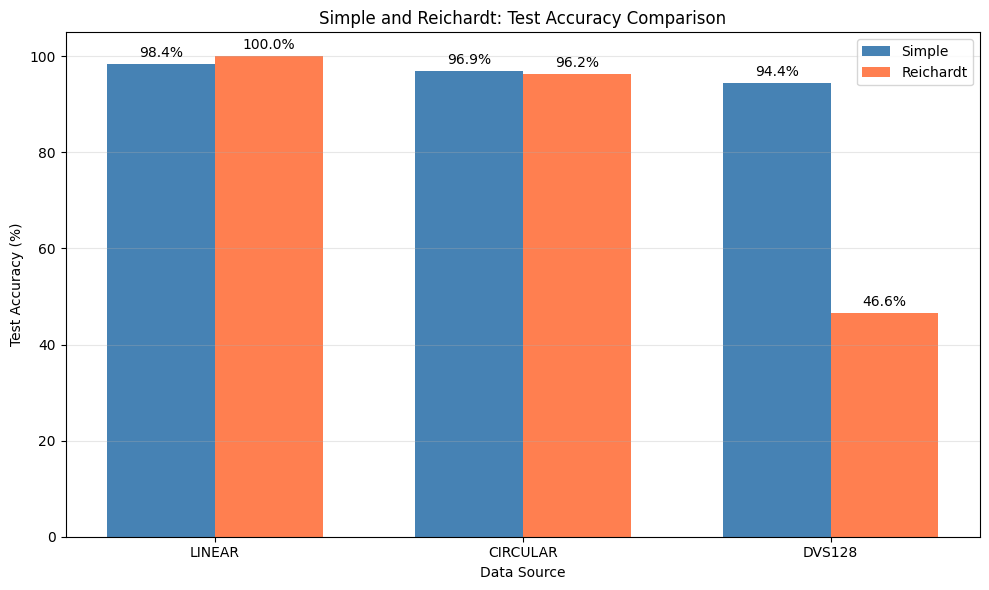

CPU times: user 503 ms, sys: 13 ms, total: 516 ms
Wall time: 1.31 s


In [ ]:
%%time

sources = ['linear', 'circular', 'dvs128']
simple_accs = [all_results['simple'][s]['test_acc'] * 100 for s in sources]
reichardt_accs = [all_results['reichardt'][s]['test_acc'] * 100 for s in sources]

x = np.arange(len(sources))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, simple_accs, width, label='Simple', color='steelblue')
bars2 = ax.bar(x + width/2, reichardt_accs, width, label='Reichardt', color='coral')

ax.set_xlabel('Data Source')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Simple and Reichardt: Test Accuracy Comparison')
ax.set_xticks(x)
ax.set_xticklabels([s.upper() for s in sources])
ax.legend()
ax.set_ylim(0, 105)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom')

for bar in bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom')

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/accuracy_comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()

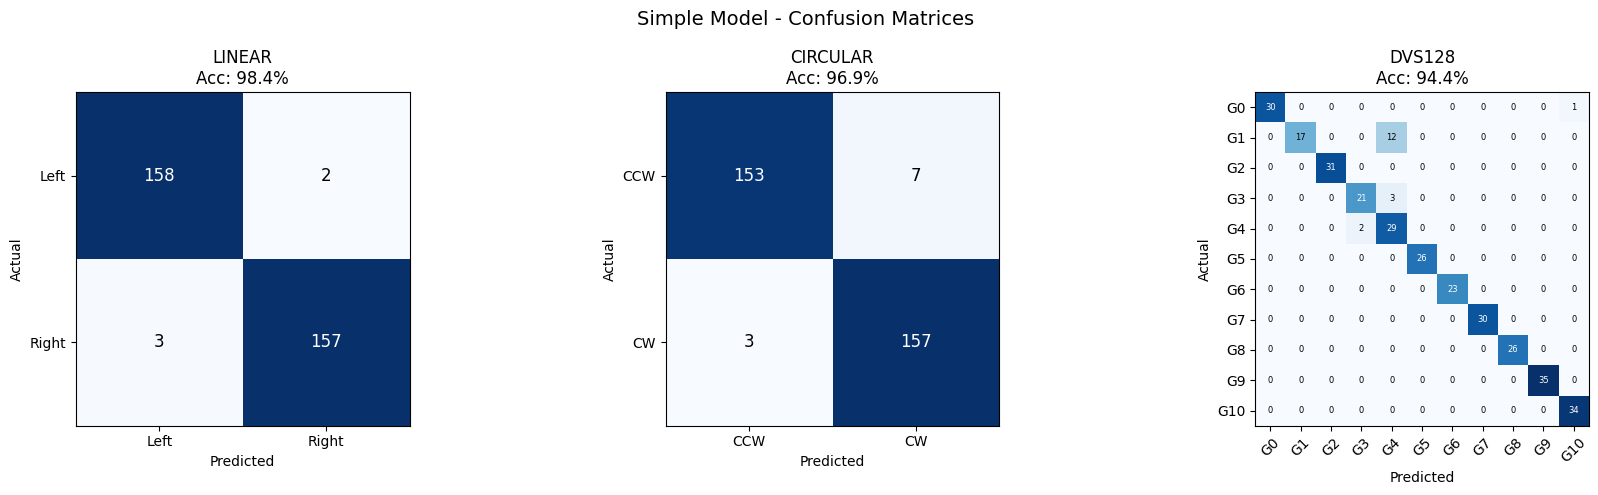

CPU times: user 1.31 s, sys: 19.2 ms, total: 1.33 s
Wall time: 2.13 s


In [ ]:
%%time

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Simple Model - Confusion Matrices', fontsize=14)

for idx, source in enumerate(['linear', 'circular', 'dvs128']):
    results = all_results['simple'][source]
    conf_matrix = results['metrics']['confusion_matrix']
    num_classes = results['num_classes']

    im = axes[idx].imshow(conf_matrix, cmap='Blues')
    axes[idx].set_xticks(range(num_classes))
    axes[idx].set_yticks(range(num_classes))

    if source == 'linear':
        labels = ['Left', 'Right']
    elif source == 'circular':
        labels = ['CCW', 'CW']
    else:
        labels = [f'G{i}' for i in range(num_classes)]

    axes[idx].set_xticklabels(labels, rotation=45 if num_classes > 5 else 0)
    axes[idx].set_yticklabels(labels)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_title(f'{source.upper()}\nAcc: {results["test_acc"]:.1%}')

    thresh = conf_matrix.max() / 2
    fontsize = 12 if num_classes <= 5 else 6
    for i in range(num_classes):
        for j in range(num_classes):
            color = 'white' if conf_matrix[i, j] > thresh else 'black'
            axes[idx].text(j, i, conf_matrix[i, j], ha='center', va='center', color=color, fontsize=fontsize)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/confusion_simple.png', dpi=150, bbox_inches='tight')
plt.show()

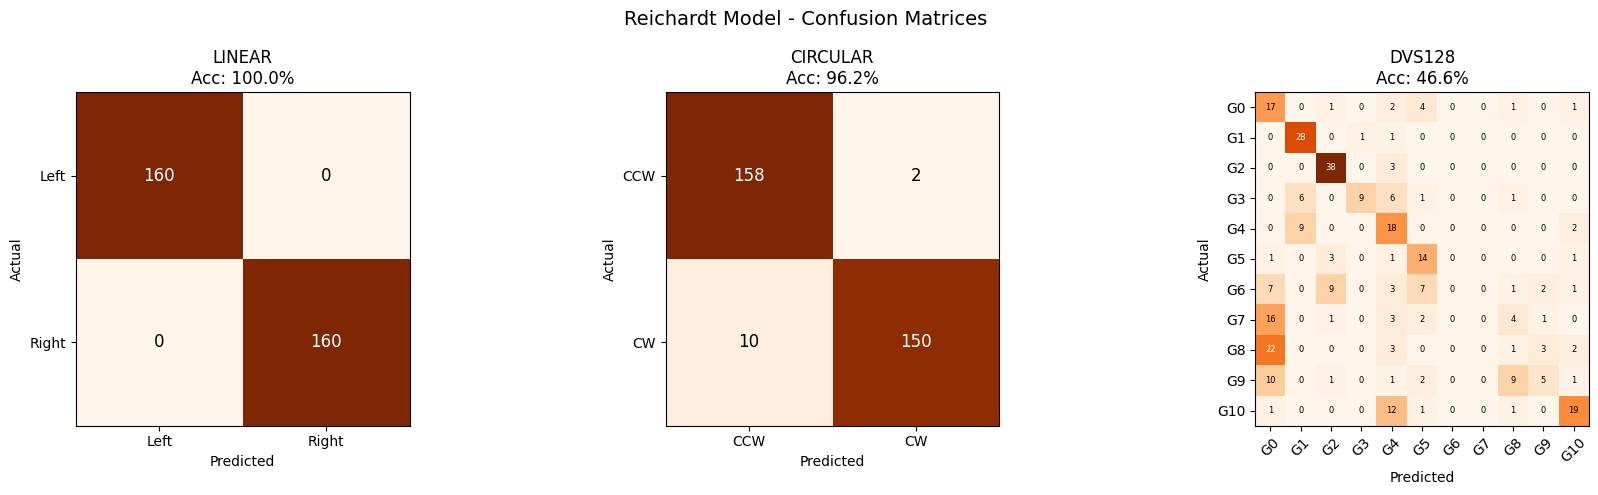

CPU times: user 1.34 s, sys: 14.4 ms, total: 1.35 s
Wall time: 2.16 s


In [ ]:
%%time

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Reichardt Model - Confusion Matrices', fontsize=14)

for idx, source in enumerate(['linear', 'circular', 'dvs128']):
    results = all_results['reichardt'][source]
    conf_matrix = results['metrics']['confusion_matrix']
    num_classes = results['num_classes']

    im = axes[idx].imshow(conf_matrix, cmap='Oranges')
    axes[idx].set_xticks(range(num_classes))
    axes[idx].set_yticks(range(num_classes))

    if source == 'linear':
        labels = ['Left', 'Right']
    elif source == 'circular':
        labels = ['CCW', 'CW']
    else:
        labels = [f'G{i}' for i in range(num_classes)]

    axes[idx].set_xticklabels(labels, rotation=45 if num_classes > 5 else 0)
    axes[idx].set_yticklabels(labels)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
    axes[idx].set_title(f'{source.upper()}\nAcc: {results["test_acc"]:.1%}')

    thresh = conf_matrix.max() / 2
    fontsize = 12 if num_classes <= 5 else 6
    for i in range(num_classes):
        for j in range(num_classes):
            color = 'white' if conf_matrix[i, j] > thresh else 'black'
            axes[idx].text(j, i, conf_matrix[i, j], ha='center', va='center', color=color, fontsize=fontsize)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/confusion_reichardt.png', dpi=150, bbox_inches='tight')
plt.show()

## Final Summary

In [ ]:
%%time

print('Final Summary')
print('-' * 50)

print('\n--- Simple Model ---')
print(f'Architecture: Input({config["data"]["num_receptors"]}) -> Hidden({config["model"]["simple"]["hidden_size"]}x2) -> Output')

print('\n--- Reichardt Model ---')
print(f'Architecture: Detectors({config["model"]["reichardt"]["num_detectors"]}) -> Hidden({config["model"]["reichardt"]["hidden_size"]}) -> Output')
print(f'Delay: {config["model"]["reichardt"]["delay_steps"]} steps, Spacing: {config["model"]["reichardt"]["detector_spacing"]} pixels')

print('\n--- Results ---')
print(f'{"Source":<15} {"Simple":<15} {"Reichardt":<15}')
print('-' * 50)
for source in ['linear', 'circular', 'dvs128']:
    simple_acc = all_results['simple'][source]['test_acc']
    reichardt_acc = all_results['reichardt'][source]['test_acc']
    print(f'{source:<15} {simple_acc:<15.2%} {reichardt_acc:<15.2%}')

print('\n--- Files ---')
print(f'Models: {CHECKPOINT_DIR}/[simple|reichardt]/')
print(f'Figures: {FIGURES_DIR}/')

Final Summary
--------------------------------------------------

--- Simple Model ---
Architecture: Input(16384) -> Hidden(32x2) -> Output

--- Reichardt Model ---
Architecture: Detectors(1024) -> Hidden(64) -> Output
Delay: 3 steps, Spacing: 4 pixels

--- Results ---
Source          Simple          Reichardt      
--------------------------------------------------
linear          98.44%          100.00%        
circular        96.88%          96.25%         
dvs128          94.38%          46.56%         

--- Files ---
Models: /content/drive/MyDrive/snn1_notebooks/results/part1_snnTorch/checkpoints/[simple|reichardt]/
Figures: /content/drive/MyDrive/snn1_notebooks/results/part1_snnTorch/figures/
CPU times: user 637 µs, sys: 0 ns, total: 637 µs
Wall time: 746 µs
